# Can violation history predict incident rate and severity at U.S. nuclear plants? An analysis of NRC inspection findings

**Name:** Mitchell Crawford and Parker Roan

### At a glance
- **Question.** Does a plant's recent violation history predict how many findings it gets and how serious they are?
- **Answer.** Yes for how many. Only weakly for how serious.
- **How many.** Each finding last year predicts 0.38 more this year. Using history cuts the average error from 6.8 to 3.8 findings per site-year.
- **How serious.** Each recent serious finding raises the odds of another by 21%. The safety area matters too (Emergency Preparedness, Security). A pile of minor findings does not.
- **Caution.** Self-revealed findings look less serious only because NRC inspectors find more Security and Emergency Preparedness issues.

*Reading guide.* Sections 1 to 5 and References follow the project document outline. The report uses the prose, the
tables, and the five figures labeled "Report figure". Everything else is supporting work. The last cell computes every
number quoted in the prose, so the text and the output agree.

The course's EDA workflow maps onto the sections like this:
- Identify the questions: section 1.
- Load the data, inspect it, and assess quality: section 2.
- Make and justify cleaning decisions, and engineer features: section 3 (features in 3.6).
- Run statistical and visual EDA: section 4.
- Save and document the result: 3.6 and the Appendix.

## 1. Introduction and analysis questions

**Domain and context.** The U.S. Nuclear Regulatory Commission (NRC) inspects every commercial nuclear power plant and
records each result as a finding or violation. Each finding gets a significance color (Green is minor, and White, Yellow,
and Red are progressively more serious) and a safety area called a cornerstone, such as Mitigating Systems or Security.

**Problem statement.** Inspectors write about 730 findings a year across 66 sites, and almost all are
minor. If a site's recent history signals how many findings it will get, and whether the next one will be serious, the
NRC and plant managers can plan inspections and corrective work around it.

**Technical barriers.**
- Serious findings are rare (4.8% of the data), so models have little to learn from.
- Counts depend on inspection effort as well as plant condition.
- The data is observational, so associations cannot show cause.
- Finding counts fell sharply after 2017, which breaks any trend learned earlier.

**Background.** The NRC describes how findings are produced and rated in its Reactor Oversight Process (NRC, NUREG-1649,
Rev. 6; NRC Management Directive 8.13). Inspectors assign each finding to a cornerstone of safety, and the significance
determination process rates it Green, White, Yellow, or Red. The NRC publishes these findings by site (NRC, Findings and
Violations dataset), and that is the data we use. This report does not review the predictive literature. It tests one
question directly on the NRC's own records: does a site's recent finding history predict its future counts and
severity once safety area and region are accounted for?

**Intended beneficiaries.** NRC regional offices (inspection planning), plant operators (deciding when minor findings
need a broader review), and safety analysts (a baseline to beat).

**Research question.**

> **Can a nuclear site's violation history help predict its future incident rate and the severity of its findings?**

- **H1 (incident rate).** A site's finding counts in the previous one and two years predict how many findings it
  receives this year, beyond the national trend and its NRC region.
- **H2 (severity).** A site's findings in the previous 24 months predict whether a new finding is high-severity, after
  controlling for cornerstone, year, identification source (NRC-identified or self-revealed), and NRC region.

## 2. Dataset description and quality assessment

**Source and provenance.** The data is the NRC's public export of reactor inspection findings and violations. NRC
inspectors record each finding in an inspection report, and the NRC publishes the results for regulatory transparency.
Each row links to its report through an ADAMS accession number. The file `findings_violations_dataset.xlsx` is our copy,
and `findings_violations_data_dictionary.xlsx` is the NRC's field list. Citation: U.S. Nuclear Regulatory Commission,
Findings and Violations dataset, https://www.nrc.gov/data. The NRC page was last updated May 13, 2025, which matches the
file's last-modified date. We added our copy to this repository on November 18, 2026.

**Scope and structure.** Each row is one finding or violation. The cell below reports the size and period.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, mean_absolute_error, r2_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Relative path: works locally and in Colab (upload the xlsx first)
raw = pd.read_excel('findings_violations_dataset.xlsx')
print(f"{raw.shape[0]:,} rows and {raw.shape[1]} columns; each row is one finding or violation")
print(f"{raw['Site Name'].nunique()} sites, {raw['Docket Number'].nunique()} dockets (units), "
      f"{raw['Report Number'].nunique()} inspection reports")
print(f"Course dataset requirements: {len(raw):,} observations (need 5,000) and {raw.shape[1]} columns (need 10 useful features), "
      f"{'met' if len(raw) >= 5000 and raw.shape[1] >= 10 else 'NOT met'}")
raw.head()

18,240 rows and 23 columns; each row is one finding or violation
66 sites, 108 dockets (units), 613 inspection reports
Course dataset requirements: 18,240 observations (need 5,000) and 23 columns (need 10 useful features), met


,Procedure,Issue Date,Report Number,Type,CornerstoneCode,Cornerstone,Title,Docket Number,Site Name,Site Code,...,Accession Number,IsTraditionalEnforcement,Item Severity Type Code,Cornerstone Attribute Type,Link,Year,Quarter,CrossCutting Area,Significance,SignificanceSort
0,71152A,2025-05-12 00:00:00,2025001,NCV,MS,Mitigating Systems,Inadequate 50.69 Alternative Treatment of a Pi...,5000352,Limerick,LIM,...,ML25121A246,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25121A246,2025,2,H,Green,1.0000
1,71152S,2025-05-12 00:00:00,2025001,NCV,MS,Mitigating Systems,Licensee Failure to Address Degrading Performa...,5000263,Monticello,MONT,...,ML25129A071,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25129A071,2025,2,P,Green,1.0000
2,71111.12,2025-05-12 00:00:00,2025001,NCV,MS,Mitigating Systems,Failure to Identify a Failure Mechanism for In...,5000390,Watts Bar,WB,...,ML25128A347,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25128A347,2025,2,P,Green,1.0000
3,71153,2025-05-12 00:00:00,2025001,FIN,IE,Initiating Events,Degradation of Main Generator Current Transfor...,5000390,Watts Bar,WB,...,ML25128A347,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25128A347,2025,2,N,Green,1.0000
4,71111.05,2025-05-12 00:00:00,2025001,NCV,IE,Initiating Events,Failure to Implement Transient Combustible Con...,5000390,Watts Bar,WB,...,ML25128A347,False,NaN,Protection Against External Factors,https://www.nrc.gov/docs/ML25128A347,2025,2,P,Green,1.0000


**Features used.** The analysis uses 14 features. The first ten come from the NRC file and the last four are built from
it (Section 3.6).

| Feature | Definition | Type and units | Relevance |
|---|---|---|---|
| `Issue Date` | Date the finding was issued | Date | Orders findings in time, so history can be built |
| `Site Name` | Plant that received the finding | Category (66 sites) | Unit for history and for clustered standard errors |
| `Region` | NRC regional office (1 to 4) | Category | Tests enforcement or risk differences (H2) |
| `Cornerstone` | Safety area of the finding | Category (8 levels) | Main control for severity |
| `Idby` | NRC-identified or self-revealed | Category | Tests who finds serious problems (H2) |
| `Significance` | Green, White, Yellow, Red, or Greater Than Green | Ordered category | Defines severity |
| `CrossCutting Area` | Organizational cause, such as human performance (H) | Category | Source of the history counts for human performance and problem identification |
| `Type` | Finding type, such as NCV or VIO | Category | Excluded from models because it follows from severity |
| `Year`, `Quarter` | Year and quarter issued | Integer | Time trend and seasonality |
| `High_Severity` | 1 if not Green, else 0 | Binary, built | Outcome for H2 |
| `Minor_Infraction_History` | Prior Green findings at the site, all time | Count, built | Baseline history measure |
| `minor_24m`, `high_24m` | Prior minor and prior high-severity findings at the site in the last 730 days | Count, built | Main predictors for H2 |
| `findings` | Findings a site received in a calendar year | Count per site-year, built | Outcome for H1 |
| `findings_lag1`, `findings_lag2` | The same count one and two years earlier | Count per site-year, built | Main predictors for H1 |

**Quality assessment.** We checked missing values, duplicates, formats, and implausible values on the raw file before
changing anything.

In [2]:
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "missing %": (raw.isna().mean() * 100).round(1), "unique": raw.nunique()})
display(quality[quality["missing"] > 0])

# Duplicates: exact, and near-duplicates (same report text and site, different row)
near_key = ["Accession Number", "Title", "Site Name", "Procedure", "Type"]
print("Exact duplicate rows:", raw.duplicated().sum())
near_dups = raw[raw.duplicated(near_key, keep=False) & raw["Accession Number"].notna()]
print("Rows sharing accession number, title, site, procedure, and type:", len(near_dups))

# Formats: Issue Date should be one type
print("\nIssue Date storage types:", raw["Issue Date"].map(lambda v: type(v).__name__).value_counts().to_dict())
as_dates = pd.to_datetime(raw["Issue Date"], errors="coerce")
print("Rows that a plain date parse puts in 1970:", (as_dates.dt.year == 1970).sum())

# Label consistency
print("\nSite names:", raw["Site Name"].nunique(), "unique;", raw["Site Name"].str.strip().str.lower().nunique(),
      "after trimming and lowercasing")
for col in ["Type", "Idby", "CrossCutting Area", "Significance"]:
    print(f"{col}: {raw[col].value_counts(dropna=False).to_dict()}")

,dtype,missing,missing %,unique
Procedure,object,1,0.0000,148
Site Code,object,171,0.9000,65
CrossCuttingAspect,object,15024,82.4000,24
Idby,object,4,0.0000,2
Accession Number,object,234,1.3000,8130
Item Severity Type Code,object,18074,99.1000,3
Cornerstone Attribute Type,object,16126,88.4000,23
SignificanceSort,float64,186,1.0000,4


Exact duplicate rows: 0
Rows sharing accession number, title, site, procedure, and type: 10

Issue Date storage types: {'datetime': 17421, 'int': 819}
Rows that a plain date parse puts in 1970: 819

Site names: 66 unique; 66 after trimming and lowercasing
Type: {'NCV': 14779, 'FIN': 2320, 'VIO': 855, 'NOV': 128, 'NCVIV': 107, 'AV': 49, 'NOVIV': 2}
Idby: {'NRC - Identified': 14067, 'Self - Revealed': 4169, nan: 4}
CrossCutting Area: {'N': 15698, 'H': 1999, 'P': 539, 'U': 2, 'X': 1, 'S': 1}
Significance: {'Green': 17357, 'White': 609, 'Greater Than Green': 186, 'Yellow': 73, 'Red': 15}


The checks found four problems.

1. **Dates stored two ways.** 819 rows hold `Issue Date` as an Excel serial number such as 37022, which a plain
   date parse turns into 1970. They are real dates from July 1999 to May 2001, and every converted year matches the
   file's `Year` column.
2. **Missing values.** `Item Severity Type Code` is 99% empty, and `Cornerstone Attribute Type` and
   `CrossCuttingAspect` are mostly empty, so we do not use them. `Site Code` is empty for all of North Anna. `Idby` is
   missing in 4 rows.
3. **Near-duplicates.** No row is an exact duplicate. 5 pairs share an accession number, title, site, and
   procedure but come from different reports or dates.
4. **Ramp-up.** Monthly counts climb through 2000 (Section 3.5), so the earliest months are not comparable with later
   years.

**Reliability and representativeness.** The source is the regulator's own record, so it is credible. It measures what
inspectors found and wrote up, not every problem, and sites that are inspected more get more findings. It covers all
66 U.S. commercial sites and says nothing about plants elsewhere.

**Suitability.** The data can show whether finding history is associated with later counts and severity. It cannot show
cause, and it cannot separate plant condition from inspection effort.

## 3. Data cleaning decisions and methods

### 3.1 Initial inspection
We examined structure with `info()` and `describe()`, counted category levels with `value_counts()`, and checked
dates, missingness, and duplicates as shown in Section 2.

In [3]:
raw.info()
raw.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18240 entries, 0 to 18239
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Procedure                   18239 non-null  object 
 1   Issue Date                  18240 non-null  object 
 2   Report Number               18240 non-null  int64  
 3   Type                        18240 non-null  object 
 4   CornerstoneCode             18240 non-null  object 
 5   Cornerstone                 18240 non-null  object 
 6   Title                       18240 non-null  object 
 7   Docket Number               18240 non-null  int64  
 8   Site Name                   18240 non-null  object 
 9   Site Code                   18069 non-null  object 
 10  CrossCuttingAspect          3216 non-null   object 
 11  Idby                        18236 non-null  object 
 12  Region                      18240 non-null  int64  
 13  Accession Number            180

,Report Number,Docket Number,Region,Year,Quarter,SignificanceSort
count,"18,240.0000","18,240.0000","18,240.0000","18,240.0000","18,240.0000","18,054.0000"
mean,"2,010,670.3404","5,000,570.5563",2.6440,"2,010.8513",2.5228,1.0829
std,"6,493.2880","6,608.8717",1.1385,6.4614,1.1098,0.4216
min,"1,999,003.0000","5,000,206.0000",1.0000,"1,999.0000",1.0000,1.0000
25%,"2,005,010.0000","5,000,285.0000",2.0000,"2,006.0000",2.0000,1.0000
50%,"2,010,008.0000","5,000,339.0000",3.0000,"2,011.0000",3.0000,1.0000
75%,"2,015,007.0000","5,000,414.0000",4.0000,"2,015.0000",3.0000,1.0000
max,"2,025,420.0000","5,200,026.0000",4.0000,"2,025.0000",4.0000,5.0000


### 3.2 Organization
We keep the NRC's column names, because the data dictionary uses them. We convert `Issue Date` to a real date. The
819 serial-number rows become dates by counting days from the Excel origin (1899-12-30). This was initially treated as incorrect data and dropped, but further inspection realized this serial-number formatting. 

In [4]:
data = raw.copy()

is_serial = data["Issue Date"].map(lambda v: isinstance(v, (int, float, np.integer)))
serial_dates = pd.Timestamp("1899-12-30") + pd.to_timedelta(data.loc[is_serial, "Issue Date"].astype(int), unit="D")
data["Issue Date"] = pd.to_datetime(data["Issue Date"].where(~is_serial), errors="coerce")
data.loc[is_serial, "Issue Date"] = serial_dates

print(f"Converted {is_serial.sum()} serial-number dates: {serial_dates.min().date()} to {serial_dates.max().date()}")
print("Converted year matches the file's Year column in every row:", bool((data["Issue Date"].dt.year == data["Year"]).all()))
data["Month"] = data["Issue Date"].dt.month
data = data.sort_values(["Site Name", "Issue Date"])

Converted 819 serial-number dates: 1999-07-29 to 2001-05-11
Converted year matches the file's Year column in every row: True


### 3.3 Missing values
- **`Site Code`.** We fill missing codes from other rows with the same site name. North Anna has no code anywhere, so it
  gets 'UNKNOWN'. The dashboard reads this column.
- **`Idby`.** We keep the 4 rows with a missing value and drop them only from the severity models that use `Idby`.
- **Sparse columns.** `Item Severity Type Code`, `Cornerstone Attribute Type`, and `CrossCuttingAspect` are mostly empty.
  We leave them unused.
- **`SignificanceSort`.** It is empty exactly where `Significance` is 'Greater Than Green', so we use `Significance`.

In [5]:
site_codes = data.dropna(subset=["Site Code"]).groupby("Site Name")["Site Code"].first()
data["Site Code"] = data["Site Code"].fillna(data["Site Name"].map(site_codes)).fillna("UNKNOWN")
print("Site Code missing after fill:", data["Site Code"].isna().sum(), "| UNKNOWN rows:", (data["Site Code"] == "UNKNOWN").sum())
print("Sites with a missing Idby row:", data.loc[data["Idby"].isna(), "Site Name"].tolist())

Site Code missing after fill: 0 | UNKNOWN rows: 171
Sites with a missing Idby row: ['Calvert Cliffs', 'Harris', 'Vogtle', 'Watts Bar']


### 3.4 Duplicates and inconsistencies
There are no exact duplicates. The 5 near-duplicate pairs differ in report number or date, so they are
separate findings and we keep them (under 0.1% of rows). Labels are consistent: site names are unique after trimming and
lowercasing, `Type`, `Idby`, and `Significance` have no spelling variants, and `Quarter` matches the issue month in every
row. The only invalid entries were the date formats fixed in Section 3.2.

### 3.5 Outliers and unusual periods
We looked at two kinds of unusual observation: very large site-years and the early ramp-up months.

Site-year counts: median 10, IQR fence 28; 61 of 1599 site-years above the fence


,Site Name,Year,findings
567,Fort Calhoun,2014,77
566,Fort Calhoun,2013,66
1041,Perry,2005,64
1271,San Onofre,2010,57
701,Indian Point,2001,54


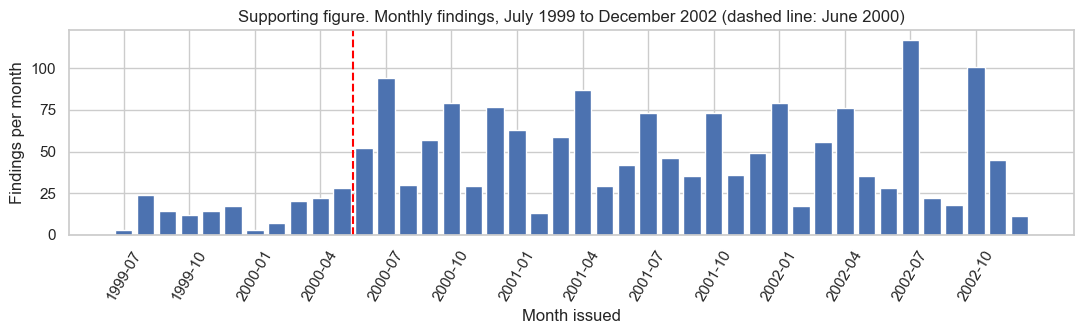

In [6]:
site_year = data.groupby(["Site Name", "Year"]).size().rename("findings").reset_index()
q1, q3 = site_year["findings"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Site-year counts: median {site_year['findings'].median():.0f}, IQR fence {upper:.0f}; "
      f"{(site_year['findings'] > upper).sum()} of {len(site_year)} site-years above the fence")
display(site_year.sort_values("findings", ascending=False).head(5))

early = data[data["Issue Date"] < "2003-01-01"].groupby(data["Issue Date"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(early.index.astype(str), early.values, color="#4C72B0")
ax.set_xticks(range(0, len(early), 3), early.index.astype(str)[::3], rotation=60)
ax.axvline(list(early.index.astype(str)).index("2000-06") - 0.5, ls="--", c="red")
ax.set_ylabel("Findings per month"); ax.set_xlabel("Month issued")
ax.set_title("Supporting figure. Monthly findings, July 1999 to December 2002 (dashed line: June 2000)")
plt.tight_layout(); plt.show()

**Large site-years.** The largest counts, such as Fort Calhoun in 2014 (77 findings), come from sites under
heightened oversight, which is the history the question is about. We keep them, and clustered standard errors limit their
pull.

**Ramp-up.** Counts rise through 2000 and level off by mid-2000. We keep the early rows but build history only from after
1 June 2000, so incomplete early months do not make a site's history look smaller than it was.

### 3.6 Transformations and new features
We build four things.

1. **Severity target.** `High_Severity` is 0 for Green and 1 for White, Yellow, Red, or Greater Than Green.
2. **All-time history.** `Minor_Infraction_History` counts a site's prior Green findings since the start of the data.
   It mostly measures how long a site has been in the data.
3. **Trailing history (finding level).** For each finding we count the same site's findings in the 730 days before its
   issue date, split into minor, high-severity, human-performance (`hp_24m`), and problem-identification (`pi_24m`)
   findings. We leave out same-day findings, which usually come from the same report, so a finding's own report never
   counts toward its history.
4. **Site-year panel (for H1).** Each site gets a row for every year from its first to its last finding, including years
   with zero findings, holding that year's count and the counts from the previous one and two years.

In [7]:
high_severity_labels = ["White", "Yellow", "Red", "Greater Than Green"]
data["High_Severity"] = data["Significance"].isin(high_severity_labels).astype(int)
data["Is_Minor"] = (data["Significance"] == "Green").astype(int)

# All-time history. shift(1) runs inside each site so a finding never counts itself.
data["Minor_Infraction_History"] = (data.groupby("Site Name")["Is_Minor"]
                                    .transform(lambda s: s.cumsum().shift(1)).fillna(0))

# Trailing 730-day history
WINDOW = np.timedelta64(730, "D")
data["one"] = 1
data["is_hp"] = (data["CrossCutting Area"] == "H").astype(int)
data["is_pi"] = (data["CrossCutting Area"] == "P").astype(int)
counted = {"total_24m": "one", "minor_24m": "Is_Minor", "hp_24m": "is_hp", "pi_24m": "is_pi", "high_24m": "High_Severity"}

def trailing_counts(g):
    d = g["Issue Date"].values
    hi = np.searchsorted(d, d, side="left")           # first row on the same date, so same-day findings are excluded
    lo = np.searchsorted(d, d - WINDOW, side="left")  # first row inside the window
    out = {}
    for name, col in counted.items():
        c = np.concatenate([[0], np.cumsum(g[col].values)])
        out[name] = c[hi] - c[lo]
    return pd.DataFrame(out, index=g.index)

trailing = pd.concat([trailing_counts(g) for _, g in data.groupby("Site Name")])

# Site-year panel
last_full_year = data["Issue Date"].max().year - 1          # the data ends in May of the last year
STEADY = pd.Timestamp("2000-06-01")                         # monthly counts level off (Section 3.5)
first_full_year = STEADY.year + 1                           # 2001
first_outcome_year = first_full_year + 2                    # 2003: both lag years are complete

span = data.groupby("Site Name")["Year"].agg(["min", "max"])
panel = pd.DataFrame([(s, y) for s, r in span.iterrows() for y in range(r["min"], r["max"] + 1)],
                     columns=["Site Name", "Year"])
counts = (data.groupby(["Site Name", "Year"])
          .agg(findings=("High_Severity", "size"), high=("High_Severity", "sum")).reset_index())
panel = panel.merge(counts, how="left", on=["Site Name", "Year"]).fillna({"findings": 0, "high": 0})
panel["Region"] = panel["Site Name"].map(data.groupby("Site Name")["Region"].first())
panel = panel.sort_values(["Site Name", "Year"])
by_site = panel.groupby("Site Name")
panel["findings_lag1"] = by_site["findings"].shift(1)
panel["findings_lag2"] = by_site["findings"].shift(2)
panel["high_lag1"] = by_site["high"].shift(1)

rate_df = panel[panel["Year"].between(first_outcome_year, last_full_year)].dropna().copy()
rate_df["year_c"] = rate_df["Year"] - 2014   # centered year (see Section 4.3)
rate_df["site_id"] = pd.factorize(rate_df["Site Name"])[0]
print(f"Site-year panel: {len(rate_df):,} site-years from {rate_df['Site Name'].nunique()} sites, "
      f"outcome years {first_outcome_year} to {last_full_year}; {(rate_df['findings'] == 0).mean():.1%} have zero findings")
trailing.describe().T

Site-year panel: 1,357 site-years from 66 sites, outcome years 2003 to 2024; 0.5% have zero findings


,count,mean,std,min,25%,50%,75%,max
total_24m,"18,240.0000",28.7623,18.1492,0.0000,16.0000,25.0000,38.0000,146.0000
minor_24m,"18,240.0000",27.2585,17.1721,0.0000,15.0000,24.0000,36.0000,138.0000
hp_24m,"18,240.0000",1.5304,4.1276,0.0000,0.0000,0.0000,0.0000,34.0000
pi_24m,"18,240.0000",0.4153,1.2750,0.0000,0.0000,0.0000,0.0000,11.0000
high_24m,"18,240.0000",1.5038,2.1979,0.0000,0.0000,0.0000,2.0000,14.0000


In [8]:
# Export the cleaned finding-level dataset for the Streamlit dashboard (target last, helper columns left out)
export_cols = [c for c in data.columns if c not in ("one", "is_hp", "is_pi", "High_Severity")] + ["High_Severity"]
data[export_cols].to_csv("cleaned_violations_data.csv", index=False)
print(f"Saved cleaned_violations_data.csv ({len(data):,} rows, {len(export_cols)} columns)")
data = data.join(trailing)

Saved cleaned_violations_data.csv (18,240 rows, 27 columns)


### 3.7 Functions and tools
We used pandas for cleaning, NumPy `searchsorted` for the trailing windows, statsmodels for regression, VIF, and clustered
errors, scikit-learn for baselines and metrics, SciPy for ANOVA and tests, and matplotlib with seaborn for figures.

### 3.8 Verification
The checks below confirm the cleaning did what we intended.

In [9]:
checks = {
    "no rows lost": len(data) == len(raw),
    "no missing or 1970 dates": bool(data["Issue Date"].notna().all() and (data["Issue Date"].dt.year > 1980).all()),
    "date year matches Year column": bool((data["Issue Date"].dt.year == data["Year"]).all()),
    "no missing Site Code": bool(data["Site Code"].notna().all()),
    "no exact duplicates": int(data.duplicated(subset=raw.columns.tolist()).sum()) == 0,
    "High_Severity equals not-Green": bool((data["High_Severity"] == (data["Significance"] != "Green")).all()),
    "first finding at every site has no history": bool((data.groupby("Site Name")["Minor_Infraction_History"].first() == 0).all()),
    "trailing history never counts the finding itself": bool((data["total_24m"] <= data.groupby("Site Name").cumcount()).all()),
    "Quarter matches issue month": bool(((data["Issue Date"].dt.month - 1) // 3 + 1 == data["Quarter"]).all()),
    "one panel row per site-year": not rate_df.duplicated(["Site Name", "Year"]).any(),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values())
print(f"\nRaw: {raw.shape}  Clean: {data[export_cols].shape}  Panel: {rate_df.shape}")

PASS  no rows lost
PASS  no missing or 1970 dates
PASS  date year matches Year column
PASS  no missing Site Code
PASS  no exact duplicates
PASS  High_Severity equals not-Green
PASS  first finding at every site has no history
PASS  trailing history never counts the finding itself
PASS  Quarter matches issue month
PASS  one panel row per site-year

Raw: (18240, 23)  Clean: (18240, 27)  Panel: (1357, 10)


## 4. Visualizations and interpretation of findings

### 4.1 Analysis approach
H1 is a count problem at the site-year level, so we use linear and polynomial regression and check its assumptions. H2 is a
yes-or-no outcome at the finding level, so we use logistic regression. We check variance inflation factors (VIF) before
fitting, cluster standard errors by site, and train every model on years through 2017 to test it on 2018 and later.

We keep `Significance`, `SignificanceSort`, and `Is_Minor` out of the models because they define the severity target. We
also drop `Type`. The NRC assigns it after judging significance, so it follows from severity, as the table shows.

**How the analysis evolved.** The first attempt used all-time minor history and found almost nothing (ROC AUC 0.55).
That sent us back to the features. We built trailing 730-day counts, removed leakage (`Type`, and a total that equals the sum
of its parts), and added the site-year panel for incident rate. The raw gap by identification source looked like a finding
until a cornerstone control erased it. Recovering the 819 serial-number dates changed every number downstream.

In [10]:
pd.crosstab(data["Type"], data["High_Severity"], margins=True)

High_Severity,0,1,All
Type,,,
AV,14,35,49
FIN,2244,76,2320
NCV,14779,0,14779
NCVIV,107,0,107
NOV,41,87,128
NOVIV,2,0,2
VIO,170,685,855
All,17357,883,18240


### 4.2 Descriptive overview

,findings,share %,% high-severity
Significance,,,
Green,17357,95.2000,0.0000
White,609,3.3000,100.0000
Greater Than Green,186,1.0000,100.0000
Yellow,73,0.4000,100.0000
Red,15,0.1000,100.0000


,findings,share %,% high-severity
Cornerstone,,,
Mitigating Systems,10104,55.4000,4.2000
Initiating Events,2780,15.2000,2.6000
Security,1809,9.9000,10.2000
Barrier Integrity,1711,9.4000,0.9000
Occupational Radiation Safety,849,4.7000,2.4000
Emergency Preparedness,547,3.0000,25.0000
Public Radiation Safety,305,1.7000,7.2000
Misc,135,0.7000,2.2000


,findings,share %,% high-severity
Idby,,,
NRC - Identified,14067,77.1000,5.3000
Self - Revealed,4169,22.9000,3.1000
NaN,4,0.0000,75.0000


,findings,share %,% high-severity
Region,,,
4,5497,30.1000,3.0000
3,4985,27.3000,5.5000
1,4233,23.2000,4.7000
2,3525,19.3000,6.9000


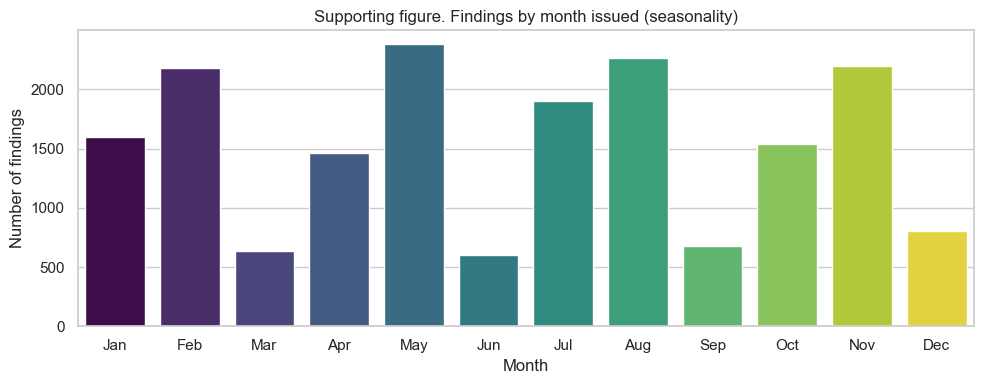

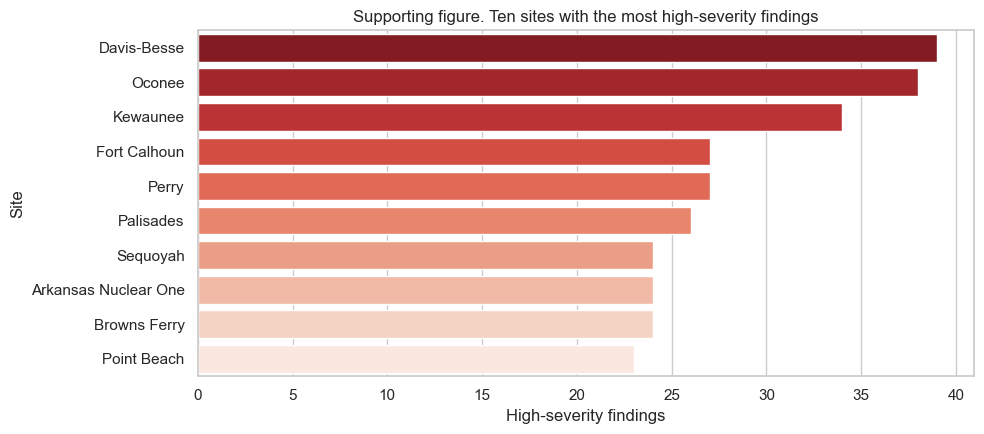

In [11]:
def freq(col):
    t = data[col].value_counts(dropna=False)
    return pd.DataFrame({"findings": t, "share %": (t / len(data) * 100).round(1),
                         "% high-severity": data.groupby(col, dropna=False)["High_Severity"].mean().mul(100).round(1).reindex(t.index)})

for col in ["Significance", "Cornerstone", "Idby", "Region"]:
    display(freq(col))

monthly = data.groupby("Month").size()
plt.figure(figsize=(10, 4))
sns.barplot(x=monthly.index, y=monthly.values, palette="viridis", hue=monthly.index, legend=False)
plt.title("Supporting figure. Findings by month issued (seasonality)")
plt.xlabel("Month"); plt.ylabel("Number of findings")
plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.tight_layout(); plt.show()

site_severity = data.groupby("Site Name")["High_Severity"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=site_severity.values, y=site_severity.index, palette="Reds_r", hue=site_severity.index, legend=False)
plt.title("Supporting figure. Ten sites with the most high-severity findings")
plt.xlabel("High-severity findings"); plt.ylabel("Site")
plt.tight_layout(); plt.show()

Findings are mostly Green (95.2%), so the outcome is imbalanced. Mitigating Systems holds 55.4% of
findings. Emergency Preparedness (25.0% high-severity) and Security (10.2%) have the highest serious shares.
Findings peak in February, May, August, and November, and the most high-severity findings are at Davis-Besse, Oconee, and Kewaunee. Findings per site-year are
right-skewed (median 10, mean 11.4).

### Report figure 1. National trend

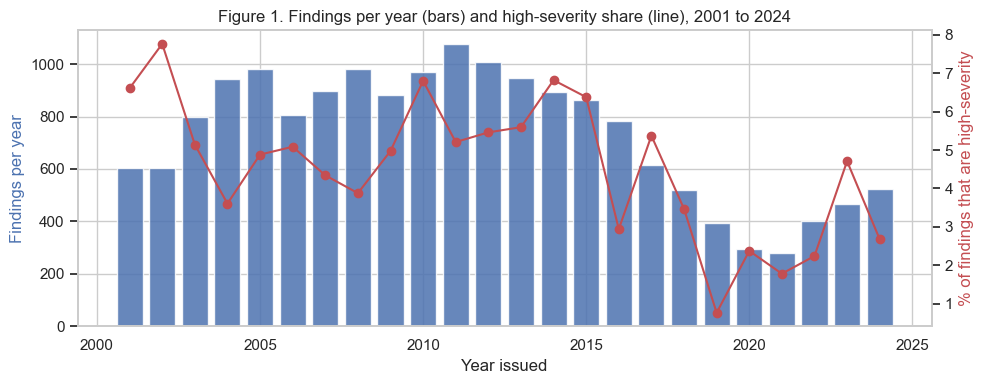

In [12]:
yearly = (data[data["Year"].between(first_full_year, last_full_year)]
          .groupby("Year").agg(findings=("High_Severity", "size"), high_rate=("High_Severity", "mean")))
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(yearly.index, yearly["findings"], color="#4C72B0", alpha=0.85)
ax1.set_xlabel("Year issued"); ax1.set_ylabel("Findings per year", color="#4C72B0")
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["high_rate"] * 100, color="#C44E52", marker="o")
ax2.set_ylabel("% of findings that are high-severity", color="#C44E52"); ax2.grid(False)
ax1.set_title("Figure 1. Findings per year (bars) and high-severity share (line), 2001 to 2024")
plt.tight_layout(); plt.show()

**Question.** How does the national volume of findings change over time?

**Pattern.** Findings peak at 1,075 in 2011 and fall to 281 in 2021. The high-severity share
is noisy and lower after 2018 (about 2.6% against 5.3% before).

**Practical meaning.** The national level moves a lot, so a model that ignores time mixes a plant's condition with the
era. Every model includes a time trend.

**Uncertainty.** The fall may reflect fewer inspections, changes to the oversight program, or safer plants, and the data
cannot separate them. 2025 is left out because the data ends in May.

### 4.3 H1. Does history predict incident rate?

**Multicollinearity.** The rate models use two lagged counts, which correlate with each other, and one model adds year
squared. Raw `Year` and `Year²` are almost perfectly collinear, and centering year before squaring fixes it.

In [13]:
def vif_table(frame, cols):
    X = sm.add_constant(frame[cols].astype(float))
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=cols, name="VIF").sort_values(ascending=False)

rate_df["year_raw"] = rate_df["Year"].astype(float)
rate_df["year_raw_sq"] = rate_df["year_raw"] ** 2
rate_df["year_c_sq"] = rate_df["year_c"] ** 2
lags = ["findings_lag1", "findings_lag2", "high_lag1"]
print("Lag correlations:"); print(rate_df[lags].corr().round(2))
vif_rate_raw = vif_table(rate_df, lags + ["year_raw", "year_raw_sq"])
vif_rate_centered = vif_table(rate_df, lags + ["year_c", "year_c_sq"])
display(pd.DataFrame({"raw year": vif_rate_raw, "centered year": vif_rate_centered}))

Lag correlations:
               findings_lag1  findings_lag2  high_lag1
findings_lag1         1.0000         0.6000     0.3900
findings_lag2         0.6000         1.0000     0.2700
high_lag1             0.3900         0.2700     1.0000


,raw year,centered year
findings_lag1,1.7537,1.7537
findings_lag2,1.6405,1.6405
high_lag1,1.1807,1.1807
year_c,NaN,1.1686
year_c_sq,NaN,1.1823
year_raw,"562,034.5237",NaN
year_raw_sq,"562,154.0958",NaN


**Shape of the time trend.** We compare polynomial degrees 1 to 3 for the national trend.

,adj R2,AIC
degree,,
1,0.0889,"9,496.4121"
2,0.1102,"9,465.3395"
3,0.1283,"9,438.3854"


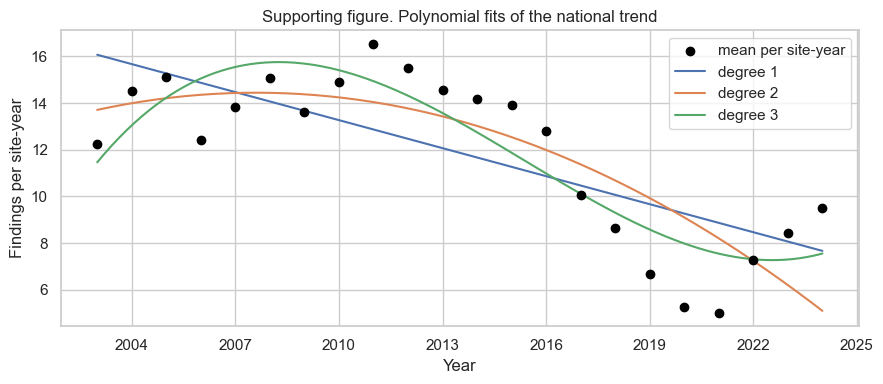

In [14]:
trend_rows, trend_fits = [], {}
terms = {1: "year_c", 2: "year_c + I(year_c**2)", 3: "year_c + I(year_c**2) + I(year_c**3)"}
for deg, rhs in terms.items():
    m = smf.ols(f"findings ~ {rhs}", rate_df).fit()
    trend_fits[deg] = m
    trend_rows.append({"degree": deg, "adj R2": m.rsquared_adj, "AIC": m.aic})
trend_tab = pd.DataFrame(trend_rows).set_index("degree")
display(trend_tab)

grid = pd.DataFrame({"year_c": np.linspace(rate_df["year_c"].min(), rate_df["year_c"].max(), 200)})
mean_by_year = rate_df.groupby("year_c")["findings"].mean()
plt.figure(figsize=(9, 4))
plt.scatter(mean_by_year.index + 2014, mean_by_year.values, c="black", zorder=3, label="mean per site-year")
for deg, m in trend_fits.items():
    plt.plot(grid["year_c"] + 2014, m.predict(grid), label=f"degree {deg}")
plt.xlabel("Year"); plt.ylabel("Findings per site-year")
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.title("Supporting figure. Polynomial fits of the national trend")
plt.legend(); plt.tight_layout(); plt.show()

**Nested models.**

| Model | Predictors | Question |
|---|---|---|
| R0 | Linear year | How much does the national trend explain? |
| R1 | R0 + NRC region | |
| R2 | R1 + findings 1 and 2 years ago + high-severity findings last year | H1: does history add to trend and region? |
| R3 | R2 + last year's findings squared | Is the history effect non-linear? |
| R4 | R2 + year squared | Does the curved trend still matter once history is in? |

In [15]:
def fit_ols(formula, frame):
    return smf.ols(formula, frame).fit(cov_type="cluster", cov_kwds={"groups": frame["site_id"]})

r_f0 = "findings ~ year_c"
r_f1 = r_f0 + " + C(Region)"
r_f2 = r_f1 + " + findings_lag1 + findings_lag2 + high_lag1"
r_f3 = r_f2 + " + I(findings_lag1**2)"
r_f4 = r_f2 + " + I(year_c**2)"
r0, r1, r2, r3, r4 = (fit_ols(f, rate_df) for f in (r_f0, r_f1, r_f2, r_f3, r_f4))

rate_models = pd.DataFrame([{"model": n, "adj R2": m.rsquared_adj, "AIC": m.aic}
                            for n, m in [("R0 time trend", r0), ("R1 + region", r1), ("R2 + history", r2),
                                         ("R3 + lag1 squared", r3), ("R4 + year squared", r4)]]).set_index("model")
display(rate_models)
print(r2.summary())
rate_coef = pd.DataFrame({"coef": r2.params, "ci_low": r2.conf_int()[0], "ci_high": r2.conf_int()[1], "p_value": r2.pvalues})
display(rate_coef.loc[["findings_lag1", "findings_lag2", "high_lag1"]])
print(f"R3: lag1^2 = {r3.params['I(findings_lag1 ** 2)']:.5f} (p = {r3.pvalues['I(findings_lag1 ** 2)']:.3g})")
print(f"R4: year^2 = {r4.params['I(year_c ** 2)']:.5f} (p = {r4.pvalues['I(year_c ** 2)']:.3g})")

,adj R2,AIC
model,,
R0 time trend,0.0889,"9,496.4121"
R1 + region,0.2404,"9,252.6372"
R2 + history,0.4281,"8,870.5183"
R3 + lag1 squared,0.4278,"8,872.2591"
R4 + year squared,0.4277,"8,872.5037"


                            OLS Regression Results                            
Dep. Variable:               findings   R-squared:                       0.431
Model:                            OLS   Adj. R-squared:                  0.428
Method:                 Least Squares   F-statistic:                     156.2
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           3.95e-38
Time:                        11:04:44   Log-Likelihood:                -4427.3
No. Observations:                1357   AIC:                             8871.
Df Residuals:                    1349   BIC:                             8912.
Df Model:                           7                                         
Covariance Type:              cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          4.1580      0.413     10.

,coef,ci_low,ci_high,p_value
findings_lag1,0.3795,0.3003,0.4587,0.0000
findings_lag2,0.1535,0.0670,0.2399,0.0005
high_lag1,0.1481,-0.3190,0.6151,0.5343


R3: lag1^2 = -0.00056 (p = 0.781)
R4: year^2 = -0.00062 (p = 0.906)


**Regression assumptions (R2).** Linear regression assumes a linear relationship, independent errors, normal residuals,
and constant variance. Figure 2 looks linear. Errors are not independent within a site, so we cluster standard errors. The
plots and tests below check the last two.

Breusch-Pagan (constant variance): p = 6.71e-23
Shapiro-Wilk (normal residuals): p = 5.9e-27


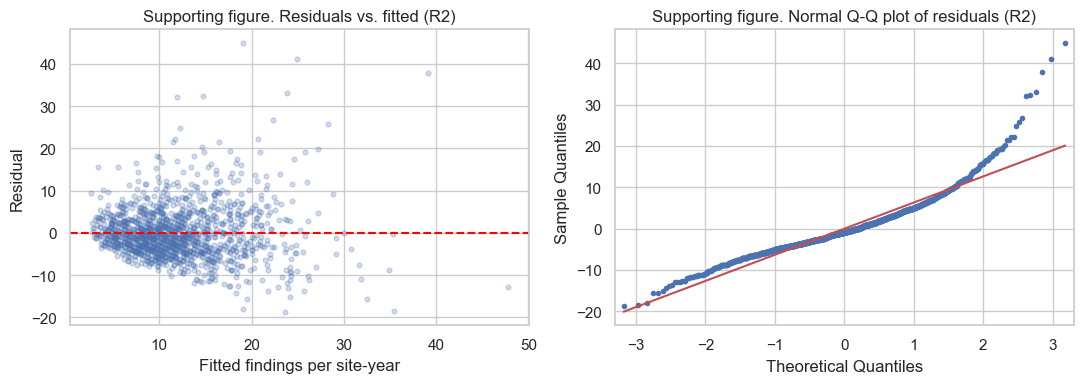

Poisson rate ratio per extra finding last year: 1.021 (p = 1.94e-30)


In [16]:
resid, fitted = r2.resid, r2.fittedvalues
bp_stat, bp_p, _, _ = sm.stats.diagnostic.het_breuschpagan(resid, r2.model.exog)
sh_stat, sh_p = stats.shapiro(resid)
print(f"Breusch-Pagan (constant variance): p = {bp_p:.3g}")
print(f"Shapiro-Wilk (normal residuals): p = {sh_p:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fitted, resid, alpha=0.25, s=12); axes[0].axhline(0, c="red", ls="--")
axes[0].set_xlabel("Fitted findings per site-year"); axes[0].set_ylabel("Residual")
axes[0].set_title("Supporting figure. Residuals vs. fitted (R2)")
sm.qqplot(resid, line="s", ax=axes[1], markersize=3)
axes[1].set_title("Supporting figure. Normal Q-Q plot of residuals (R2)")
plt.tight_layout(); plt.show()

# Counts: Poisson regression with the same predictors as a robustness check
pois = smf.glm("findings ~ year_c + C(Region) + findings_lag1 + findings_lag2 + high_lag1", rate_df,
               family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": rate_df["site_id"]})
pois_rr = np.exp(pois.params)
print(f"Poisson rate ratio per extra finding last year: {pois_rr['findings_lag1']:.3f} "
      f"(p = {pois.pvalues['findings_lag1']:.3g})")

The residuals fan out as fitted values grow (Breusch-Pagan p < 0.001) and have heavy right tails (Shapiro-Wilk
p < 0.001), as counts usually do. Clustered standard errors stay valid when variance is not constant. A Poisson model with
the same predictors agrees: each extra finding last year multiplies this year's expected count by 1.02.

**Region.** Region adds a lot of fit to R1. A one-way ANOVA on each site's mean findings per year (one value per site, so
observations are independent) tests whether regions differ.

In [17]:
site_means = rate_df.groupby(["Site Name", "Region"])["findings"].mean().reset_index()
groups = [g["findings"].values for _, g in site_means.groupby("Region")]
F, p_anova = stats.f_oneway(*groups)
grand = site_means["findings"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = ((site_means["findings"] - grand) ** 2).sum()
eta2 = ss_between / ss_total
print(f"One-way ANOVA of site mean findings per year across regions: F = {F:.2f}, p = {p_anova:.3g}, eta-squared = {eta2:.2f}")
print(site_means.groupby("Region")["findings"].agg(["count", "mean", "std"]).round(2))

One-way ANOVA of site mean findings per year across regions: F = 26.69, p = 3.32e-11, eta-squared = 0.56
        count    mean    std
Region                      
1          18  9.9700 3.6500
2          18  8.5200 2.1000
3          16 13.5300 2.8300
4          14 17.8200 3.9300


Regions differ in volume (F = 26.7, p < 0.001, eta-squared 0.56). Region 4 sites get about 4 more
findings a year than Region 1 sites with similar history, yet Region 2 gets the fewest findings and has the highest odds of
a serious one. The data cannot say whether that reflects plant condition or inspector behavior.

**Out-of-time validation.** We train on 2003 to 2017, test on 2018 to 2024, and compare with a naive forecast (the same
count as last year). MAE is the average error in findings per site-year. R² goes negative when the test period's level
shifts in a way earlier years cannot foresee. Within-year Spearman asks whether the model ranks sites correctly inside each
test year, which isolates what history adds apart from the national level.

In [18]:
rtrain, rtest = rate_df[rate_df["Year"] <= 2017], rate_df[rate_df["Year"] >= 2018]
print(f"train: {len(rtrain):,} site-years, test: {len(rtest):,} site-years")
nat_mean = rate_df.groupby("Year")["findings"].mean()

def within_year_spearman(pred):
    t = rtest[["Year", "findings"]].assign(pred=np.asarray(pred))
    vals = [g["findings"].corr(g["pred"], method="spearman") for _, g in t.groupby("Year") if g["pred"].nunique() > 1]
    return np.mean(vals) if vals else np.nan   # NaN for a year-only model: every site gets the same prediction

def scores(name, pred):
    return {"model": name, "MAE": mean_absolute_error(rtest["findings"], pred),
            "R2": r2_score(rtest["findings"], pred), "within-year Spearman": within_year_spearman(pred)}

rows = [scores("Naive: same as last year", rtest["findings_lag1"])]
preds = {}
for name, f in [("R0 time trend", r_f0), ("R1 + region", r_f1), ("R2 + history", r_f2), ("R4 + year squared", r_f4)]:
    preds[name] = smf.ols(f, rtrain).fit().predict(rtest)
    rows.append(scores(name, preds[name]))
rate_scores = pd.DataFrame(rows).set_index("model")
display(rate_scores)

train: 962 site-years, test: 395 site-years


,MAE,R2,within-year Spearman
model,,,
Naive: same as last year,3.9215,-0.3142,0.3932
R0 time trend,6.9038,-1.6425,NaN
R1 + region,6.8089,-1.8362,0.2936
R2 + history,3.8173,-0.0335,0.4138
R4 + year squared,4.1886,-0.3498,0.4111


### Report figure 2. Last year predicts this year

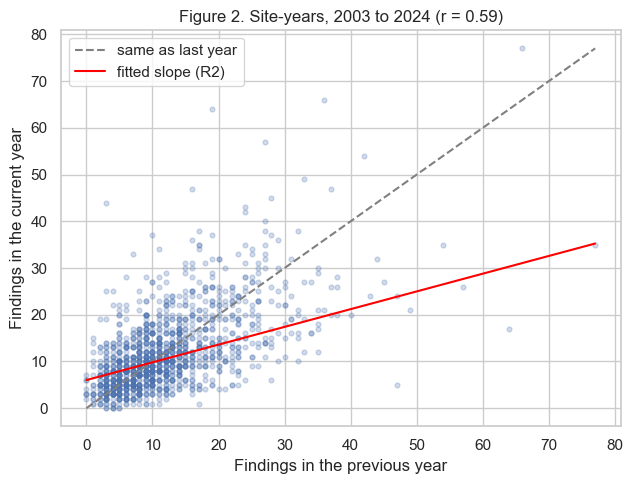

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(rate_df["findings_lag1"], rate_df["findings"], alpha=0.25, s=12)
lim = rate_df[["findings", "findings_lag1"]].max().max()
ax.plot([0, lim], [0, lim], ls="--", c="grey", label="same as last year")
xs = np.linspace(0, lim, 100)
ax.plot(xs, r2.params["Intercept"] + r2.params["findings_lag1"] * xs + r2.params["findings_lag2"] * rate_df["findings_lag2"].mean(), c="red", label="fitted slope (R2)")
ax.set_xlabel("Findings in the previous year"); ax.set_ylabel("Findings in the current year")
ax.set_title(f"Figure 2. Site-years, {first_outcome_year} to {last_full_year} (r = {rate_df['findings'].corr(rate_df['findings_lag1']):.2f})")
ax.legend(); plt.tight_layout(); plt.show()

**Question.** Does a site's count last year predict its count this year?

**Pattern.** Yes (r = 0.59). In R2, each extra finding last year predicts 0.38 more this year (95% CI
0.30 to 0.46), and each finding two years ago predicts 0.15 more. History lifts adjusted R² from
0.24 (year and region) to 0.43. Last year's high-severity count adds nothing (p = 0.53), and neither does a
squared lag (p = 0.78) or squared year (p = 0.91).

**Practical meaning.** Sites with many findings keep getting many. On 2018 to 2024 the history model has the lowest error
(3.8 findings per site-year, against 6.8 without history and 3.9 for the naive forecast) and ranks
sites best within each year (Spearman 0.41, against 0.29 for region alone). Planners can use last year's counts
to anticipate workload.

**Uncertainty.** No model foresees the national drop after 2017 (average findings per site-year fell from 14 in
2015 to 5 in 2021), so out-of-time R² is below zero (-0.03). History says which sites get more findings, not
the national level. Counts also reflect inspection effort.

### Report figure 3. Out-of-time check

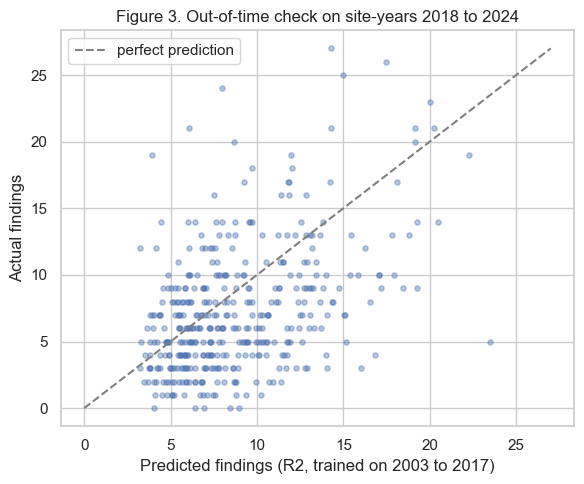

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(preds["R2 + history"], rtest["findings"], alpha=0.4, s=14)
lim = max(rtest["findings"].max(), preds["R2 + history"].max())
ax.plot([0, lim], [0, lim], ls="--", c="grey", label="perfect prediction")
ax.set_xlabel("Predicted findings (R2, trained on 2003 to 2017)"); ax.set_ylabel("Actual findings")
ax.set_title("Figure 3. Out-of-time check on site-years 2018 to 2024")
ax.legend(); plt.tight_layout(); plt.show()

**Question.** Do the model's predictions hold up on years it never saw?

**Pattern.** Predictions follow the ranking of sites but run high on average, because the model learned from years with
higher counts. The average over-prediction is 1.5 findings per site-year.

**Practical meaning.** Use the model to compare sites within a year, not to forecast the national total.

**Uncertainty.** The 2018 to 2024 period includes the COVID-19 years, so it is a hard test.

### 4.4 H2. Does history predict severity?

**Multicollinearity.** Every finding is minor or high-severity, so `total_24m` equals `minor_24m + high_24m` exactly. That
is perfect multicollinearity: the VIFs are infinite (hence the divide-by-zero warning) and no model can estimate all three
coefficients. We drop `total_24m`. The severity sample keeps findings issued at least 730 days after 1 June 2000, so every
trailing window is complete.

Severity sample: 16,786 findings from 2002-06-01, 802 high-severity (4.78%)
           total_24m  minor_24m  hp_24m  pi_24m  high_24m  year_c
total_24m     1.0000     0.9900 -0.1700 -0.1400    0.4600 -0.1800
minor_24m     0.9900     1.0000 -0.1600 -0.1300    0.3600 -0.1700
hp_24m       -0.1700    -0.1600  1.0000  0.7700   -0.1400  0.6300
pi_24m       -0.1400    -0.1300  0.7700  1.0000   -0.1400  0.5500
high_24m      0.4600     0.3600 -0.1400 -0.1400    1.0000 -0.1400
year_c       -0.1800    -0.1700  0.6300  0.5500   -0.1400  1.0000


statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,before,after dropping total_24m
high_24m,inf,1.1621
hp_24m,2.9528,2.9528
minor_24m,inf,1.1714
pi_24m,2.5336,2.5336
total_24m,inf,NaN
year_c,1.7166,1.7166


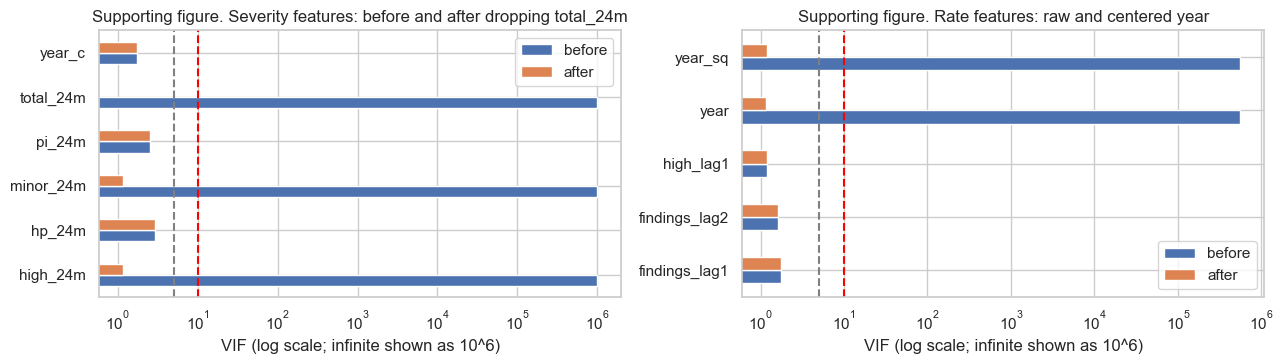

In [21]:
sev_start = STEADY + pd.Timedelta(days=730)
sev_df = data[data["Issue Date"] >= sev_start].dropna(subset=["Idby"]).reset_index(drop=True)
sev_df["year_c"] = sev_df["Year"] - 2014
sev_df["site_id"] = pd.factorize(sev_df["Site Name"])[0]
print(f"Severity sample: {len(sev_df):,} findings from {sev_start.date()}, "
      f"{sev_df['High_Severity'].sum()} high-severity ({sev_df['High_Severity'].mean():.2%})")

hist_all = ["total_24m", "minor_24m", "hp_24m", "pi_24m", "high_24m", "year_c"]
print(sev_df[hist_all].corr().round(2))
vif_sev_before = vif_table(sev_df, hist_all)
vif_sev_after = vif_table(sev_df, ["minor_24m", "hp_24m", "pi_24m", "high_24m", "year_c"])
display(pd.DataFrame({"before": vif_sev_before, "after dropping total_24m": vif_sev_after}))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, before, after, title in [
        (axes[0], vif_sev_before, vif_sev_after, "Severity features: before and after dropping total_24m"),
        (axes[1], vif_rate_raw.rename(lambda s: s.replace("year_raw", "year")),
         vif_rate_centered.rename(lambda s: s.replace("year_c", "year")), "Rate features: raw and centered year")]:
    pd.DataFrame({"before": before.replace(np.inf, 1e6), "after": after}).plot.barh(ax=ax)
    ax.axvline(5, ls="--", c="grey"); ax.axvline(10, ls="--", c="red")
    ax.set_xscale("log"); ax.set_xlabel("VIF (log scale; infinite shown as 10^6)"); ax.set_title("Supporting figure. " + title)
plt.tight_layout(); plt.show()

`hp_24m` and `pi_24m` correlate with each other and with year, because the NRC coded cross-cutting aspects more often in
later years. Their VIFs stay below 5, so we keep both.

**Baseline.** The project's first model predicts `High_Severity` from all-time `Minor_Infraction_History` and `Month` with
logistic regression (balanced class weights, random 80/20 split). A dummy classifier that always predicts the base rate sets
the floor.

              precision    recall  f1-score   support

           0       0.96      0.47      0.64      3471
           1       0.06      0.64      0.11       177

    accuracy                           0.48      3648
   macro avg       0.51      0.56      0.37      3648
weighted avg       0.92      0.48      0.61      3648

Baseline ROC AUC: 0.551   Dummy ROC AUC: 0.500


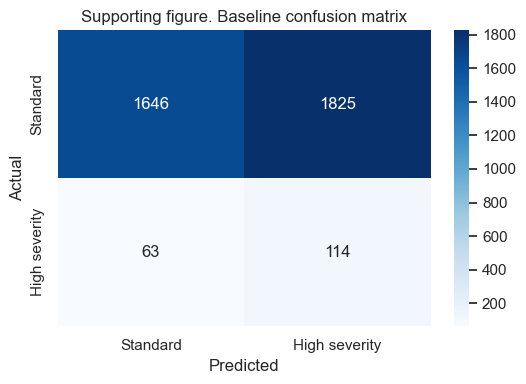

Average prior minor findings, standard: 149.6 | high-severity: 133.0


In [22]:
X = data[["Minor_Infraction_History", "Month"]].fillna(0)
y = data["High_Severity"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(class_weight="balanced", random_state=42).fit(X_train, y_train)
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
base_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
dummy_auc = roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1])
print(classification_report(y_test, model.predict(X_test)))
print(f"Baseline ROC AUC: {base_auc:.3f}   Dummy ROC AUC: {dummy_auc:.3f}")

plt.figure(figsize=(5.5, 4))
sns.heatmap(confusion_matrix(y_test, model.predict(X_test)), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Standard", "High severity"], yticklabels=["Standard", "High severity"])
plt.title("Supporting figure. Baseline confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()
print("Average prior minor findings, standard:", round(data.loc[data.High_Severity == 0, "Minor_Infraction_History"].mean(), 1),
      "| high-severity:", round(data.loc[data.High_Severity == 1, "Minor_Infraction_History"].mean(), 1))

### Report figure 4. Severity by group and recent history

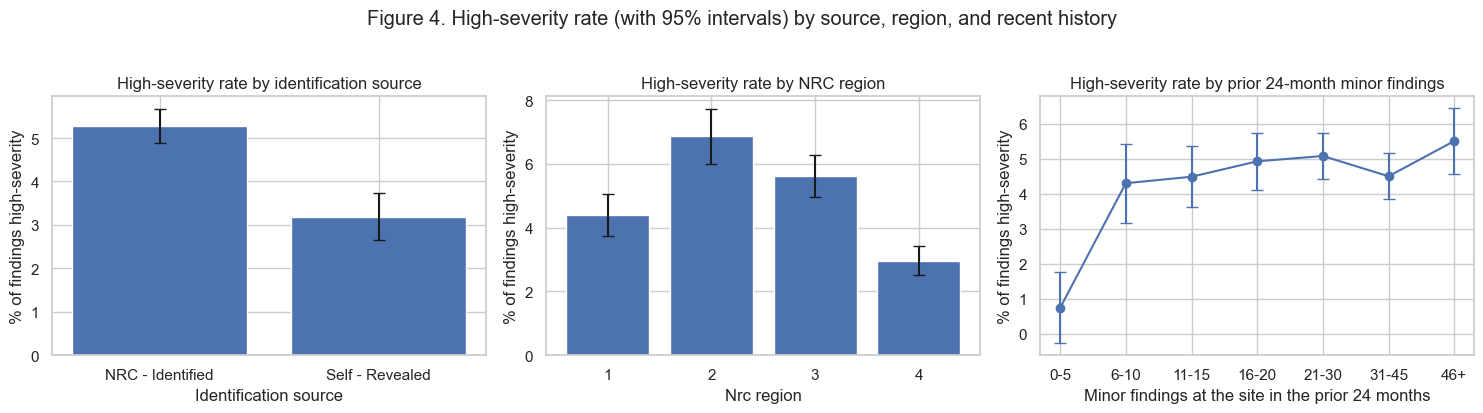

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in [(axes[0], "Idby", "identification source"), (axes[1], "Region", "NRC region")]:
    s = sev_df.groupby(col)["High_Severity"].agg(["mean", "count"])
    se = np.sqrt(s["mean"] * (1 - s["mean"]) / s["count"])
    ax.bar(s.index.astype(str), s["mean"] * 100, yerr=1.96 * se * 100, capsize=4, color="#4C72B0")
    ax.set_title(f"High-severity rate by {title}"); ax.set_ylabel("% of findings high-severity"); ax.set_xlabel(title.capitalize())
bins = pd.cut(sev_df["minor_24m"], [-1, 5, 10, 15, 20, 30, 45, 1000], labels=["0-5", "6-10", "11-15", "16-20", "21-30", "31-45", "46+"])
s = sev_df.groupby(bins, observed=True)["High_Severity"].agg(["mean", "count"])
se = np.sqrt(s["mean"] * (1 - s["mean"]) / s["count"])
axes[2].errorbar(s.index.astype(str), s["mean"] * 100, yerr=1.96 * se * 100, marker="o", capsize=4)
axes[2].set_title("High-severity rate by prior 24-month minor findings")
axes[2].set_xlabel("Minor findings at the site in the prior 24 months"); axes[2].set_ylabel("% of findings high-severity")
fig.suptitle("Figure 4. High-severity rate (with 95% intervals) by source, region, and recent history", y=1.03)
plt.tight_layout(); plt.show()

**Question.** Which groups and which levels of recent history have more high-severity findings?

**Pattern.** NRC-identified findings are high-severity more often than self-revealed ones, and Region 2 more often than
Region 4. The rate jumps from 0.7% for sites with 0 to 5 recent minor findings to about 4.8% for sites with
more, then stays flat.

**Practical meaning.** A site with almost no recent findings rarely has a serious one. Beyond that, more minor findings do
not raise the rate.

**Uncertainty.** These are raw rates. The identification-source gap comes from the cornerstone mix (see below).

**Nested models.**

| Model | Predictors |
|---|---|
| M0 | Cornerstone + year |
| M1 | M0 + identification source + region |
| M2 | M1 + recent history, with a squared term for minor findings (tests H2) |

No model includes both site and region, because each site belongs to one region.

In [24]:
controls = "C(Cornerstone, Treatment('Mitigating Systems')) + year_c"
f0 = f"High_Severity ~ {controls}"
f1 = f0 + " + C(Idby) + C(Region)"
f2 = f1 + " + minor_24m + I(minor_24m**2) + hp_24m + pi_24m + high_24m"

def fit_logit(formula, frame):
    return smf.logit(formula, frame).fit(disp=False, cov_type="cluster", cov_kwds={"groups": frame["site_id"]})

m0, m1, m2 = (fit_logit(f, sev_df) for f in (f0, f1, f2))
sev_models = pd.DataFrame([{"model": n, "k": int(m.df_model), "AIC": m.aic, "BIC": m.bic, "McFadden R2": m.prsquared}
                           for n, m in [("M0 controls", m0), ("M1 + Idby + Region", m1), ("M2 + history", m2)]]).set_index("model")
display(sev_models)
for a, b, label in [(m0, m1, "M0 to M1"), (m1, m2, "M1 to M2")]:
    stat = 2 * (b.llf - a.llf); dof = b.df_model - a.df_model
    print(f"{label}: LR chi2 = {stat:.1f}, df = {dof:.0f}, p = {stats.chi2.sf(stat, dof):.2e} (ignores clustering, so p is too small)")
print(m2.summary())

,k,AIC,BIC,McFadden R2
model,,,,
M0 controls,8,"6,006.2945","6,075.8492",0.0706
M1 + Idby + Region,12,"5,918.5635","6,019.0314",0.0854
M2 + history,17,"5,761.2935","5,900.4029",0.1114


M0 to M1: LR chi2 = 95.7, df = 4, p = 7.97e-20 (ignores clustering, so p is too small)
M1 to M2: LR chi2 = 167.3, df = 5, p = 2.79e-34 (ignores clustering, so p is too small)
                           Logit Regression Results                           
Dep. Variable:          High_Severity   No. Observations:                16786
Model:                          Logit   Df Residuals:                    16768
Method:                           MLE   Df Model:                           17
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1114
Time:                        11:04:46   Log-Likelihood:                -2862.6
converged:                       True   LL-Null:                       -3221.6
Covariance Type:              cluster   LLR p-value:                1.408e-141
                                                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------

,odds_ratio,ci_low,ci_high,p_value
Cornerstone: Barrier Integrity,0.2111,0.0943,0.4724,0.0002
Cornerstone: Emergency Preparedness,7.1279,4.9202,10.3264,0.0000
Cornerstone: Initiating Events,0.6344,0.3563,1.1295,0.1220
Cornerstone: Misc,0.2007,0.0260,1.5524,0.1239
Cornerstone: Occupational Radiation Safety,0.5205,0.1928,1.4055,0.1976
Cornerstone: Public Radiation Safety,1.9055,0.9283,3.9117,0.0789
Cornerstone: Security,3.1812,2.3873,4.2390,0.0000
Idby: Self - Revealed,0.9447,0.6052,1.4746,0.8022
Region 2,1.8008,1.2865,2.5209,0.0006
Region 3,1.2289,0.8335,1.8120,0.2980


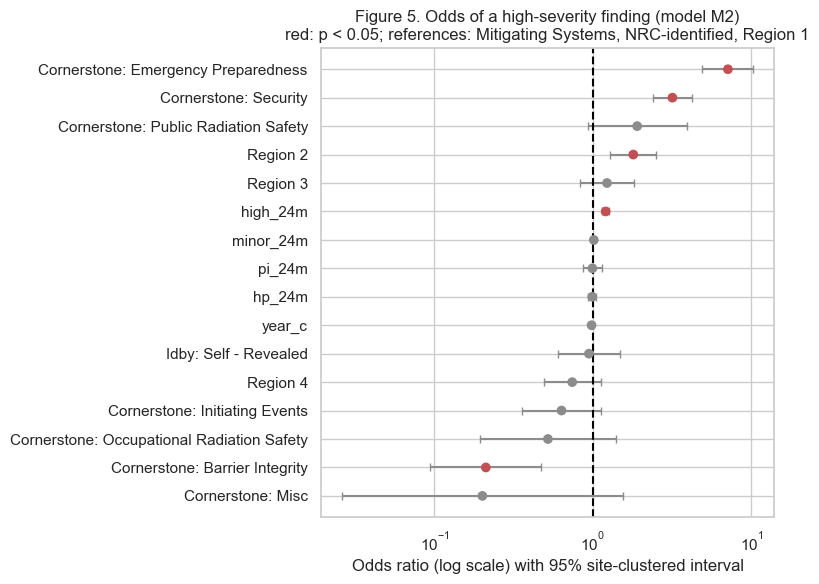

In [25]:
def pretty(name):
    name = name.replace("C(Cornerstone, Treatment('Mitigating Systems'))[T.", "Cornerstone: ")
    name = name.replace("C(Idby)[T.", "Idby: ").replace("C(Region)[T.", "Region ")
    return name.rstrip("]")

ci = m2.conf_int()
or_table = pd.DataFrame({"odds_ratio": np.exp(m2.params), "ci_low": np.exp(ci[0]),
                         "ci_high": np.exp(ci[1]), "p_value": m2.pvalues}).drop("Intercept")
or_table.index = [pretty(i) for i in or_table.index]
display(or_table)

plot_df = or_table.drop(index=["I(minor_24m ** 2)"], errors="ignore").sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 6))
colors = np.where(plot_df["p_value"] < 0.05, "#C44E52", "#8C8C8C")
ax.errorbar(plot_df["odds_ratio"], range(len(plot_df)),
            xerr=[plot_df["odds_ratio"] - plot_df["ci_low"], plot_df["ci_high"] - plot_df["odds_ratio"]],
            fmt="none", ecolor="#8C8C8C", capsize=3)
ax.scatter(plot_df["odds_ratio"], range(len(plot_df)), c=colors, zorder=3)
ax.axvline(1, ls="--", c="black")
ax.set_yticks(range(len(plot_df)), plot_df.index)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (log scale) with 95% site-clustered interval")
ax.set_title("Figure 5. Odds of a high-severity finding (model M2)\nred: p < 0.05; references: Mitigating Systems, NRC-identified, Region 1")
plt.tight_layout(); plt.show()

### Report figure 5. Odds of a high-severity finding
**Question.** After controlling for cornerstone and year, which factors raise the odds that a finding is high-severity?

**Pattern.** Emergency Preparedness (odds ratio 7.1) and Security (3.2) findings are the most likely to be
high-severity, and Region 2 has 1.80 times the odds of Region 1 (95% CI 1.29 to 2.52). Each
high-severity finding at the site in the prior 24 months raises the odds by 21% (OR 1.21, 95% CI
1.15 to 1.26). Human-performance and problem-identification counts add nothing.

**Practical meaning.** Safety area and recent serious findings are the warning signs. A run of minor findings is not.

**Uncertainty.** These are associations, and the model is weak (McFadden R² 0.11). Two checks follow.

**Identification source.** Self-revealed findings look less severe on their own. We add controls one at a time to see
whether the gap survives, and compare the cornerstone mix of the two groups.

In [26]:
k = "C(Idby)[T.Self - Revealed]"
rows = []
for label, f in [("Idby only", "High_Severity ~ C(Idby)"), ("+ Cornerstone and year", f"High_Severity ~ C(Idby) + {controls}"),
                 ("+ Region (M1)", f1), ("+ history (M2)", f2)]:
    m = fit_logit(f, sev_df)
    rows.append({"model": label, "OR self-revealed": np.exp(m.params[k]), "p": m.pvalues[k]})
idby_tab = pd.DataFrame(rows).set_index("model")
display(idby_tab)
display(pd.crosstab(sev_df["Cornerstone"], sev_df["Idby"], normalize="columns").mul(100).round(1))

,OR self-revealed,p
model,,
Idby only,0.5910,0.0055
+ Cornerstone and year,0.8992,0.6470
+ Region (M1),0.8923,0.6229
+ history (M2),0.9447,0.8022


Idby,NRC - Identified,Self - Revealed
Cornerstone,,
Barrier Integrity,8.7000,11.7000
Emergency Preparedness,3.5000,0.7000
Initiating Events,10.4000,31.7000
Misc,0.8000,0.1000
Mitigating Systems,59.5000,40.9000
Occupational Radiation Safety,3.1000,9.1000
Public Radiation Safety,1.5000,2.3000
Security,12.5000,3.6000


The gap disappears once cornerstone is in the model (odds ratio 0.59 alone, 0.90 with controls,
p = 0.65). NRC inspectors find a larger share of Security and Emergency Preparedness findings, the two riskiest
cornerstones, so source is a confounder, not a cause.

**Is the minor-findings effect curved?** The squared term is significant (p = 0.01), with predicted risk peaking
near 37 prior minor findings. Figure 4 looks more like a jump and a plateau, and a quadratic always bends down, so we
compare it with `log(1 + minor_24m)`.

Quadratic: AIC = 5761.3 | Log: AIC = 5766.4 | turning point = 37.1 minor findings
linear p = 0.139, quadratic p = 0.015, log term p = 0.627


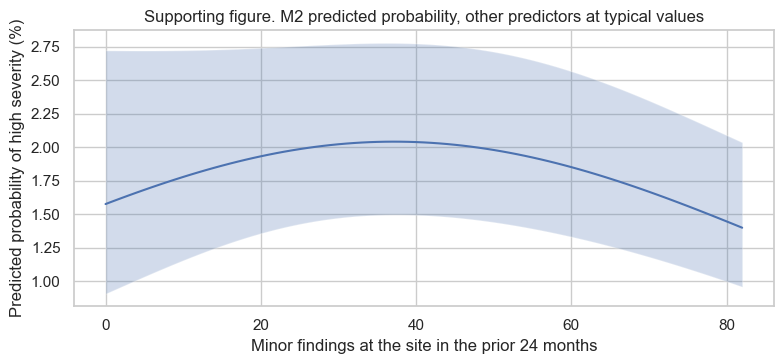

In [27]:
m2_log = fit_logit(f1 + " + np.log1p(minor_24m) + hp_24m + pi_24m + high_24m", sev_df)
b1, b2 = m2.params["minor_24m"], m2.params["I(minor_24m ** 2)"]
turn = -b1 / (2 * b2)
print(f"Quadratic: AIC = {m2.aic:.1f} | Log: AIC = {m2_log.aic:.1f} | turning point = {turn:.1f} minor findings")
print(f"linear p = {m2.pvalues['minor_24m']:.3f}, quadratic p = {m2.pvalues['I(minor_24m ** 2)']:.3f}, "
      f"log term p = {m2_log.pvalues['np.log1p(minor_24m)']:.3f}")

hi_q = sev_df["minor_24m"].quantile(0.99)
grid = pd.DataFrame({"minor_24m": np.arange(0, int(hi_q) + 1)})
for col in ["Cornerstone", "Idby", "Region"]:
    grid[col] = sev_df[col].mode()[0]
for col in ["hp_24m", "pi_24m", "high_24m", "year_c"]:
    grid[col] = sev_df[col].median()
pred = m2.get_prediction(grid).summary_frame(alpha=0.05)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(grid["minor_24m"], pred["predicted"] * 100)
ax.fill_between(grid["minor_24m"], pred["ci_lower"] * 100, pred["ci_upper"] * 100, alpha=0.25)
ax.set_xlabel("Minor findings at the site in the prior 24 months"); ax.set_ylabel("Predicted probability of high severity (%)")
ax.set_title("Supporting figure. M2 predicted probability, other predictors at typical values")
plt.tight_layout(); plt.show()

The quadratic beats the log form only slightly (AIC 5761.3 against 5766.4) and the confidence band is wide, so
the curve is weak evidence of a plateau, not a decline.

**Out-of-time validation.** We train on findings through 2017 and test on 2018 and later. Accuracy says little at a 5% base
rate, so we report ROC AUC (how well a model ranks findings) and average precision (PR-AUC) against the test base rate.

In [28]:
strain, stest = sev_df[sev_df["Year"] <= 2017], sev_df[sev_df["Year"] >= 2018]
print(f"train n = {len(strain):,} ({strain['High_Severity'].mean():.2%} high), test n = {len(stest):,} ({stest['High_Severity'].mean():.2%} high)")
rows = [{"model": "Dummy (always the base rate)", "ROC AUC": 0.5, "PR-AUC": stest["High_Severity"].mean(),
         "base rate": stest["High_Severity"].mean()}]
for name, f in [("Baseline: all-time history + month", "High_Severity ~ Minor_Infraction_History + Month"),
                ("M0 controls", f0), ("M1 + Idby + Region", f1), ("M2 + recent history", f2)]:
    p = smf.logit(f, strain).fit(disp=False).predict(stest)
    rows.append({"model": name, "ROC AUC": roc_auc_score(stest["High_Severity"], p),
                 "PR-AUC": average_precision_score(stest["High_Severity"], p), "base rate": stest["High_Severity"].mean()})
sev_scores = pd.DataFrame(rows).set_index("model")
sev_scores

train n = 13,784 (5.21% high), test n = 3,002 (2.80% high)


,ROC AUC,PR-AUC,base rate
model,,,
Dummy (always the base rate),0.5000,0.0280,0.0280
Baseline: all-time history + month,0.5537,0.0300,0.0280
M0 controls,0.5984,0.0426,0.0280
M1 + Idby + Region,0.5928,0.0503,0.0280
M2 + recent history,0.6380,0.0673,0.0280


The full model reaches ROC AUC 0.64 and PR-AUC 0.067 on 2018 and later, about 2.4 times the
2.8% base rate. Controls alone reach 0.60, and the all-time baseline reaches 0.55, close to the
dummy.

### 4.5 Synthesis

| Hypothesis | Verdict | Evidence |
|---|---|---|
| H1. History predicts incident rate | Supported | Each finding last year predicts 0.38 more this year. Out-of-time error falls from 6.8 to 3.8 findings per site-year. |
| H2. History predicts severity | Weak | All-time minor history is no better than chance (ROC AUC 0.55). Each recent serious finding raises the odds by 21%. The full model reaches ROC AUC 0.64. |

History tells you which sites will have more findings, not how many the whole country will have. Serious findings seem to
come from specific failures, not from a buildup of minor ones. None of this shows cause: more findings may mean more
inspection, or the same underlying weakness showing up repeatedly.

## 5. Conclusions and limitations

**Answer to the research question.** Yes for incident rate and only weakly for severity. A site's recent history predicts
how many findings it will receive, but adds little to predicting whether a given finding is serious.

**Key findings.**
1. Each finding last year predicts 0.38 more this year, and the history model ranks sites better than region and trend
   alone on 2018 to 2024.
2. Severity is hard to predict. Only recent serious findings (odds ratio 1.21 each) and the safety area (Emergency
   Preparedness, Security) carry a signal.
3. Self-revealed findings only look less serious. The gap disappears once cornerstone is controlled.

**Practical implications.** The NRC can use last year's counts as a first guide to where inspection hours will be needed.
It should treat a site's recent serious findings, not its pile of minor ones, as the trigger for a deeper review.

**Limitations.**
- **Data.** Counts reflect inspection effort and only what inspectors wrote up. The first months are a ramp-up period.
- **Sample.** Only 883 findings are high-severity, and the 2018 to 2024 test period contains a structural break.
- **Omitted variables.** The data has no plant age, reactor type, outage schedule, or inspection hours.
- **Methods.** Residuals show non-constant variance and heavy tails, so we rely on clustered standard errors (a Poisson model
  agrees). Region differences cannot be split into enforcement and plant risk.

**Future work.** Add inspection hours and plant characteristics, fit negative binomial or mixed-effects count models, model
severity as ordered (Green to Red), and test whether changes to the oversight program after 2017 produced a measurable
break.

## References

U.S. Nuclear Regulatory Commission. Findings and Violations dataset and data dictionary.
https://www.nrc.gov/data (page last updated May 13, 2025).

## Appendix. Dashboard export and numbers quoted in the text
The first cell saves the fitted coefficients to `model_coefficients.json`, so the Streamlit dashboard uses exactly the models
in this notebook. The second cell computes every number the prose quotes, so the text can be checked against the model output.

In [29]:
def levels(params, prefix):
    return {k.split("[T.")[1].rstrip("]"): float(v) for k, v in params.items() if k.startswith(prefix)}

coefs = {
    "meta": {
        "year_center": 2014,
        "last_full_year": int(last_full_year),
        "latest_date": str(data["Issue Date"].max().date()),
        "window_days": 730,
        "reference": {"cornerstone": "Mitigating Systems", "idby": "NRC - Identified", "region": "1"},
        "rate_out_of_time_mae": round(float(rate_scores.loc["R2 + history", "MAE"]), 2),
        "rate_naive_mae": round(float(rate_scores.loc["Naive: same as last year", "MAE"]), 2),
        "severity_out_of_time_auc": round(float(sev_scores.loc["M2 + recent history", "ROC AUC"]), 3),
        "severity_base_rate": round(float(sev_df["High_Severity"].mean()), 4),
    },
    "rate": {
        "intercept": float(r2.params["Intercept"]),
        "region": levels(r2.params, "C(Region)"),
        "year_c": float(r2.params["year_c"]),
        "findings_lag1": float(r2.params["findings_lag1"]),
        "findings_lag2": float(r2.params["findings_lag2"]),
        "high_lag1": float(r2.params["high_lag1"]),
    },
    "severity": {
        "intercept": float(m2.params["Intercept"]),
        "cornerstone": levels(m2.params, "C(Cornerstone"),
        "idby_self_revealed": float(m2.params["C(Idby)[T.Self - Revealed]"]),
        "region": levels(m2.params, "C(Region)"),
        "year_c": float(m2.params["year_c"]),
        "minor_24m": float(m2.params["minor_24m"]),
        "minor_24m_sq": float(m2.params["I(minor_24m ** 2)"]),
        "hp_24m": float(m2.params["hp_24m"]),
        "pi_24m": float(m2.params["pi_24m"]),
        "high_24m": float(m2.params["high_24m"]),
    },
}
with open("model_coefficients.json", "w") as fh:
    json.dump(coefs, fh, indent=2)
print("Saved model_coefficients.json:", {k: len(v) for k, v in coefs.items()})

# Check the dashboard's prediction formulas against statsmodels on every row we fitted
try:
    from nrc_model import predict_rate, predict_severity
    chk_r = rate_df.apply(lambda x: predict_rate(coefs, int(x["Region"]), int(x["Year"]), x["findings_lag1"],
                                                 x["findings_lag2"], x["high_lag1"]), axis=1)
    chk_s = sev_df.apply(lambda x: predict_severity(coefs, x["Cornerstone"], x["Idby"] == "Self - Revealed", int(x["Region"]),
                                                    int(x["Year"]), x["minor_24m"], x["hp_24m"], x["pi_24m"], x["high_24m"]), axis=1)
    diff_r = float(np.abs(chk_r - r2.predict(rate_df)).max())
    diff_s = float(np.abs(chk_s - m2.predict(sev_df)).max())
    print(f"Dashboard formulas vs statsmodels, largest difference: rate {diff_r:.1e}, severity {diff_s:.1e}")
    assert diff_r < 1e-8 and diff_s < 1e-8
except ImportError:
    print("nrc_model.py is not next to the notebook, so the dashboard check was skipped")

Saved model_coefficients.json: {'meta': 9, 'rate': 6, 'severity': 10}
Dashboard formulas vs statsmodels, largest difference: rate 7.1e-15, severity 2.2e-16


In [30]:
def n0(x): return f"{x:,.0f}"
def n1(x): return f"{x:.1f}"
def n2(x): return f"{x:.2f}"
def n3(x): return f"{x:.3f}"
def pv(x): return "< 0.001" if x < 0.001 else f"= {x:.2f}" if x >= 0.01 else f"= {x:.3f}"

K = {}
K["n_raw"] = n0(len(raw)); K["n_clean"] = n0(len(data)); K["n_sites"] = str(data["Site Name"].nunique())
K["n_serial"] = n0(is_serial.sum()); K["pct_serial"] = n1(is_serial.mean() * 100)
K["pct_item_sev_missing"] = n0(raw["Item Severity Type Code"].isna().mean() * 100)
K["high_pct"] = n1(data["High_Severity"].mean() * 100); K["green_pct"] = n1((data["Significance"] == "Green").mean() * 100)
full_years = data[data["Year"].between(first_full_year, last_full_year)].groupby("Year").size()
K["per_year"] = n0(round(full_years.mean(), -1))
K["peak_year"] = str(full_years.idxmax()); K["peak_n"] = n0(full_years.max())
post = full_years[full_years.index > full_years.idxmax()]
K["low_year"] = str(post.idxmin()); K["low_n"] = n0(post.min())
yr = data[data["Year"].between(first_full_year, last_full_year)].groupby("Year")["High_Severity"].mean()
K["late_high_pct"] = n1(yr[yr.index >= 2018].mean() * 100); K["early_high_pct"] = n1(yr[yr.index < 2018].mean() * 100)
cs = data.groupby("Cornerstone")["High_Severity"].mean() * 100
K["ep_pct"] = n1(cs["Emergency Preparedness"]); K["sec_pct"] = n1(cs["Security"])
K["ms_pct"] = n1((data["Cornerstone"] == "Mitigating Systems").mean() * 100)
mn = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
top_m = data.groupby("Month").size().sort_values(ascending=False).head(4).index.sort_values()
K["top_months"] = ", ".join(mn[m - 1] for m in top_m[:-1]) + ", and " + mn[top_m[-1] - 1]
K["top_sites"] = ", ".join(site_severity.index[:2]) + ", and " + site_severity.index[2]
K["sy_median"] = n0(site_year["findings"].median()); K["sy_mean"] = n1(site_year["findings"].mean())
mx = site_year.sort_values("findings", ascending=False).iloc[0]
K["max_sy_n"] = n0(mx["findings"])
# rate models
K["r_lag1"] = n2(rate_df["findings"].corr(rate_df["findings_lag1"]))
K["lag1"] = n2(r2.params["findings_lag1"]); K["lag1_lo"] = n2(r2.conf_int().loc["findings_lag1", 0]); K["lag1_hi"] = n2(r2.conf_int().loc["findings_lag1", 1])
K["lag2"] = n2(r2.params["findings_lag2"])
K["adj_r1"] = n2(r1.rsquared_adj); K["adj_r2"] = n2(r2.rsquared_adj)
K["hl_p"] = pv(r2.pvalues["high_lag1"]); K["lag_sq_p"] = pv(r3.pvalues["I(findings_lag1 ** 2)"]); K["yr_sq_p"] = pv(r4.pvalues["I(year_c ** 2)"])
K["mae_r2"] = n1(rate_scores.loc["R2 + history", "MAE"]); K["mae_r1"] = n1(rate_scores.loc["R1 + region", "MAE"])
K["mae_naive"] = n1(rate_scores.loc["Naive: same as last year", "MAE"])
K["sp_r2"] = n2(rate_scores.loc["R2 + history", "within-year Spearman"]); K["sp_r1"] = n2(rate_scores.loc["R1 + region", "within-year Spearman"])
K["r2_oot"] = n2(rate_scores.loc["R2 + history", "R2"])
K["m2015"] = n0(nat_mean[2015]); K["m2021"] = n0(nat_mean[2021])
K["reg4"] = n0(r2.params["C(Region)[T.4]"])
K["bias"] = n1((preds["R2 + history"] - rtest["findings"]).mean())
K["bp_p"] = pv(bp_p); K["sh_p"] = pv(sh_p); K["pois_rr"] = n2(pois_rr["findings_lag1"])
K["anova_f"] = n1(F); K["anova_p"] = pv(p_anova); K["eta2"] = n2(eta2)
# severity models
K["bin_rate"] = n1(s["mean"].iloc[1:].mean() * 100); K["bin0"] = n1(s["mean"].iloc[0] * 100)
K["near_pairs"] = str(len(near_dups) // 2)
K["or_ep"] = n1(or_table.loc["Cornerstone: Emergency Preparedness", "odds_ratio"]); K["or_sec"] = n1(or_table.loc["Cornerstone: Security", "odds_ratio"])
K["or_r2"] = n2(or_table.loc["Region 2", "odds_ratio"]); K["or_r2_lo"] = n2(or_table.loc["Region 2", "ci_low"]); K["or_r2_hi"] = n2(or_table.loc["Region 2", "ci_high"])
K["or_hi"] = n2(or_table.loc["high_24m", "odds_ratio"]); K["or_hi_lo"] = n2(or_table.loc["high_24m", "ci_low"]); K["or_hi_hi"] = n2(or_table.loc["high_24m", "ci_high"])
K["or_hi_pct"] = n0((or_table.loc["high_24m", "odds_ratio"] - 1) * 100)
K["mcf"] = n2(m2.prsquared)
K["idby_raw"] = n2(idby_tab.iloc[0, 0]); K["idby_adj"] = n2(idby_tab.iloc[1, 0]); K["idby_p"] = pv(idby_tab.iloc[1, 1])
K["minor_sq_p"] = pv(m2.pvalues["I(minor_24m ** 2)"]); K["turn"] = n0(turn)
K["aic_quad"] = n1(m2.aic); K["aic_log"] = n1(m2_log.aic)
K["auc_m2"] = n2(sev_scores.loc["M2 + recent history", "ROC AUC"]); K["pr_m2"] = n3(sev_scores.loc["M2 + recent history", "PR-AUC"])
K["test_base"] = n1(stest["High_Severity"].mean() * 100)
K["pr_ratio"] = n1(sev_scores.loc["M2 + recent history", "PR-AUC"] / stest["High_Severity"].mean())
K["auc_m0"] = n2(sev_scores.loc["M0 controls", "ROC AUC"]); K["auc_base_oot"] = n2(sev_scores.loc["Baseline: all-time history + month", "ROC AUC"])
K["auc_base"] = n2(base_auc); K["sev_high"] = n0(data["High_Severity"].sum())
print("KEYNUMS " + json.dumps(K))
K

KEYNUMS {"n_raw": "18,240", "n_clean": "18,240", "n_sites": "66", "n_serial": "819", "pct_serial": "4.5", "pct_item_sev_missing": "99", "high_pct": "4.8", "green_pct": "95.2", "per_year": "730", "peak_year": "2011", "peak_n": "1,075", "low_year": "2021", "low_n": "281", "late_high_pct": "2.6", "early_high_pct": "5.3", "ep_pct": "25.0", "sec_pct": "10.2", "ms_pct": "55.4", "top_months": "February, May, August, and November", "top_sites": "Davis-Besse, Oconee, and Kewaunee", "sy_median": "10", "sy_mean": "11.4", "max_sy_n": "77", "r_lag1": "0.59", "lag1": "0.38", "lag1_lo": "0.30", "lag1_hi": "0.46", "lag2": "0.15", "adj_r1": "0.24", "adj_r2": "0.43", "hl_p": "= 0.53", "lag_sq_p": "= 0.78", "yr_sq_p": "= 0.91", "mae_r2": "3.8", "mae_r1": "6.8", "mae_naive": "3.9", "sp_r2": "0.41", "sp_r1": "0.29", "r2_oot": "-0.03", "m2015": "14", "m2021": "5", "reg4": "4", "bias": "1.5", "bp_p": "< 0.001", "sh_p": "< 0.001", "pois_rr": "1.02", "anova_f": "26.7", "anova_p": "< 0.001", "eta2": "0.56", "bi

{'n_raw': '18,240',
 'n_clean': '18,240',
 'n_sites': '66',
 'n_serial': '819',
 'pct_serial': '4.5',
 'pct_item_sev_missing': '99',
 'high_pct': '4.8',
 'green_pct': '95.2',
 'per_year': '730',
 'peak_year': '2011',
 'peak_n': '1,075',
 'low_year': '2021',
 'low_n': '281',
 'late_high_pct': '2.6',
 'early_high_pct': '5.3',
 'ep_pct': '25.0',
 'sec_pct': '10.2',
 'ms_pct': '55.4',
 'top_months': 'February, May, August, and November',
 'top_sites': 'Davis-Besse, Oconee, and Kewaunee',
 'sy_median': '10',
 'sy_mean': '11.4',
 'max_sy_n': '77',
 'r_lag1': '0.59',
 'lag1': '0.38',
 'lag1_lo': '0.30',
 'lag1_hi': '0.46',
 'lag2': '0.15',
 'adj_r1': '0.24',
 'adj_r2': '0.43',
 'hl_p': '= 0.53',
 'lag_sq_p': '= 0.78',
 'yr_sq_p': '= 0.91',
 'mae_r2': '3.8',
 'mae_r1': '6.8',
 'mae_naive': '3.9',
 'sp_r2': '0.41',
 'sp_r1': '0.29',
 'r2_oot': '-0.03',
 'm2015': '14',
 'm2021': '5',
 'reg4': '4',
 'bias': '1.5',
 'bp_p': '< 0.001',
 'sh_p': '< 0.001',
 'pois_rr': '1.02',
 'anova_f': '26.7',
 'a